# Patrones de éxito en videojuegos

## Descripción del proyecto

Se cuenta con datos históricos (hasta 2016) de ventas por región, géneros, plataformas, reseñas de usuarios y críticos, y la clasificación ESRB de cada juego.

El objetivo es identificar los patrones que determinan si un juego tiene éxito, para detectar proyectos prometedores y planificar las campañas publicitarias de 2017 (el análisis se plantea como si fuera diciembre de 2016).

**Descripción de los datos:**

| Columna | Descripción |
|---|---|
| Name | Nombre del juego |
| Platform | Plataforma |
| Year_of_Release | Año de lanzamiento |
| Genre | Género |
| NA_sales | Ventas en Norteamérica (millones de USD) |
| EU_sales | Ventas en Europa (millones de USD) |
| JP_sales | Ventas en Japón (millones de USD) |
| Other_sales | Ventas en otros países (millones de USD) |
| Critic_Score | Calificación de críticos (máximo 100) |
| User_Score | Calificación de usuarios (máximo 10) |
| Rating | Clasificación ESRB |

**¿Qué se hizo?**

1. Abrir el archivo y estudiar la información general.
2. Preparar los datos: nombres de columnas, tipos de datos, valores ausentes, duplicados y ventas totales.
3. Analizar los datos: lanzamientos por año, ciclo de vida de las plataformas, periodo relevante, plataformas líderes, reseñas vs. ventas y géneros.
4. Crear un perfil de usuario para cada región (NA, UE, JP).
5. Probar hipótesis sobre las calificaciones de usuarios.
6. Escribir una conclusión general.


## Paso 1. Leer el dataset e importar librerías necesarias

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats as st

Se carga el archivo. Se guarda una copia del dataframe original para no modificarlo.

In [2]:

df_raw = pd.read_csv('datasets/games.csv')

df = df_raw.copy()

Revisamos la información general: tamaño, tipos de datos y valores no nulos.

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


In [4]:
display(df.sample(5, random_state=1))

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
14230,Rakushou! Pachi-Slot Sengen 5: Rio Paradise,PS2,2007.0,Misc,0.00,0.00,0.03,0.00,NaN,NaN,NaN
14043,Nobunaga's Ambition II,3DS,2015.0,Strategy,0.00,0.00,0.04,0.00,NaN,NaN,NaN
3158,Up,DS,2009.0,Action,0.30,0.27,0.00,0.07,NaN,tbd,E
22,Super Mario Bros. 3,NES,1988.0,Platform,9.54,3.44,3.84,0.46,NaN,NaN,NaN
110,Mario Kart 8,WiiU,2014.0,Racing,3.15,2.15,1.28,0.51,88.0,9.1,E


In [5]:
display(df.describe())

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


Contamos los valores ausentes por columna (absolutos y en porcentaje) y los duplicados.

In [6]:
ausentes = pd.DataFrame({'ausentes': df.isna().sum(),
                         'porcentaje': (df.isna().mean() * 100).round(2)})
display(ausentes)

,ausentes,porcentaje
Name,2,0.01
Platform,0,0.00
Year_of_Release,269,1.61
Genre,2,0.01
NA_sales,0,0.00
EU_sales,0,0.00
JP_sales,0,0.00
Other_sales,0,0.00
Critic_Score,8578,51.32
User_Score,6701,40.09


In [7]:
print('Filas duplicadas completas:', df.duplicated().sum())
print('Duplicados por nombre, plataforma y año:', df.duplicated(subset=['Name', 'Platform', 'Year_of_Release']).sum())

Filas duplicadas completas: 0
Duplicados por nombre, plataforma y año: 2


**Observaciones del Paso 1:**

1. El dataset tiene 16,715 registros y 11 columnas. Los nombres de las columnas tienen mayúsculas.
2. Tipos de datos a corregir: `Year_of_Release` es float (un año debe ser entero) y `User_Score` es object porque contiene el texto `tbd`.
3. Hay valores ausentes en `Name` y `Genre` (2), `Year_of_Release` (269, 1.6 %), y una gran cantidad en `Critic_Score` (51 %), `User_Score` (40 %) y `Rating` (40 %).
4. No hay filas completamente duplicadas, pero hay 2 duplicados por nombre, plataforma y año que se revisarán.
5. Las ventas tienen medianas muy bajas comparadas con sus máximos: pocos juegos concentran la mayoría de las ventas.

Se tratarán en ese orden.

## Paso 2. Preparar los datos

### 2.1 Nombres de las columnas

Pasamos los nombres de las columnas a minúsculas.

In [8]:
df.columns = df.columns.str.lower()
display(df.columns)

Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='object')

### 2.2 Tipos de datos

Haremos year_of_release a int

In [9]:
df['year_of_release'] = df['year_of_release'].astype('Int64')
print((df['year_of_release']).dtype)

Int64


Como la columna presenta datos nulos, el tipo de datos "int" no es suficiente así que se tomó el tipo de datos "Int64" que soporta los datos nulos.

### 2.3 Tratamiento de "tbd" en user_score

`tbd` significa *to be determined* (a determinar): el juego todavía no tiene suficientes reseñas de usuarios para publicar una calificación. En la práctica equivale a no tener calificación, por eso se tratará como valor ausente (`NaN`).

Obtendremos una serie de los registros donde user_score tuvieran tbd solo por si se requirieran en un futuro y ya con la copia de la serie, entonces los sustituimos por nulos y cambiamos a float la columna.

In [10]:
user_score_tbd = df['user_score'][df['user_score']=='tbd'].copy()
user_score_tbd.count()

2424

In [11]:
df['user_score'] = df['user_score'].replace('tbd', np.nan)
df['user_score'] = df['user_score'].astype('float64')
print((df['user_score']).dtype)

float64


Ya deberían tener los tipos correctos, revisemos con info

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
dtypes: Int64(1), float64(6), object(4)
memory usage: 1.4+ MB


Con estos pasos, hemos conseguido tener los tipos de datos correctos.

Los cuales fueron:
1. year_of_release a int pues los años se manejan a números enteros por la naturaleza que los representa sin contar el mes en el que se lanzó el juego.
2. user_score a float pues algunos registros presentaban "tbd" y esto convertía toda la columna a tipo object. Se guardó una serie con los registros donde tuvieran "tbd", sin embargo al no ser necesarios y dificultar los cálculos posteriores se convirtieron en valores nulos y se pasó la columna a tipo de datos float.

`critic_score` se queda como float: aunque sus valores son enteros, tiene muchos nulos y para los cálculos (correlaciones, promedios) float es suficiente.

### 2.4 Valores ausentes

Se identificó que hay registros con nombre y genero nulos, pero con los registros de las ventas intactas así que se conservarán para contar en la estadística. Se muestran a continuación esos dos registros.

In [13]:
display(df[df['name'].isnull()])

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,NaN,GEN,1993,NaN,1.78,0.53,0.00,0.08,NaN,NaN,NaN
14244,NaN,GEN,1993,NaN,0.00,0.00,0.03,0.00,NaN,NaN,NaN


Son dos juegos de 1993 de la consola Genesis (GEN). Probablemente el registro se perdió al recopilar la información de una fuente antigua. Como son de 1993, quedarán fuera del periodo que se usará para el pronóstico, así que no afectan el análisis.

**Decisiones para el resto de las columnas con ausentes:**

| Columna | Decisión |
|---|---|
| `year_of_release` (269) |Se dejan como nulos: son solo el 1.6 % y rellenarlos con un promedio inventaría años. Quedan fuera del análisis por año. |
| `critic_score` (51 %) | Se dejan como nulos: rellenarlos con la media o mediana alteraría las correlaciones con las ventas. |
| `user_score` (40 % + tbd) | Se dejan como nulos por la misma razón. |
| `rating` (40 %) | Se rellenan con `'unknown'` para poder analizarlos como una categoría propia en el perfil por región. |

In [14]:
df['rating'] = df['rating'].fillna('unknown')
display(df['rating'].value_counts())

unknown    6766
E          3990
T          2961
M          1563
E10+       1420
EC            8
RP            3
K-A           3
AO            1
Name: rating, dtype: int64

### 2.5 Duplicados

Revisamos los registros duplicados por nombre, plataforma y año.

In [15]:
duplicados = df[df.duplicated(subset=['name', 'platform', 'year_of_release'], keep=False)]
display(duplicados)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
604,Madden NFL 13,PS3,2012,Sports,2.11,0.22,0.00,0.23,83.0,5.5,E
659,NaN,GEN,1993,NaN,1.78,0.53,0.00,0.08,NaN,NaN,unknown
14244,NaN,GEN,1993,NaN,0.00,0.00,0.03,0.00,NaN,NaN,unknown
16230,Madden NFL 13,PS3,2012,Sports,0.00,0.01,0.00,0.00,83.0,5.5,E


Además de los dos registros sin nombre de GEN (que son juegos distintos, porque no tienen el mismo nombre conocido), aparece *Madden NFL 13* para PS3 dos veces. El segundo registro solo tiene 0.01 en ventas de Europa, parece una venta que se capturó por separado. Se suma esa venta al primer registro y se elimina el duplicado.

In [16]:
df.loc[604, 'eu_sales'] = df.loc[604, 'eu_sales'] + df.loc[16230, 'eu_sales']
df = df.drop(index=16230).reset_index(drop=True)
print('Duplicados de Madden NFL 13:', df[df['name']=='Madden NFL 13'].duplicated(subset=['name', 'platform', 'year_of_release']).sum())

Duplicados de Madden NFL 13: 0


### 2.6 Ventas totales

Por último para la sección de preparación de los datos se creará una columna nueva con las ventas totales de cada juego, siendo esta la suma de las ventas en todas las regiones.

In [17]:
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']
display(df.sample(5, random_state=1))

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
13569,Minna ga Shuyaku no NHK Kouhaku Quiz Kassen,Wii,2009,Misc,0.00,0.00,0.04,0.00,NaN,NaN,unknown,0.04
14042,Harry Potter and the Prisoner of Azkaban,PC,2004,Action,0.00,0.03,0.00,0.00,67.0,7.2,E,0.03
3158,Up,DS,2009,Action,0.30,0.27,0.00,0.07,NaN,NaN,E,0.64
22,Super Mario Bros. 3,NES,1988,Platform,9.54,3.44,3.84,0.46,NaN,NaN,unknown,17.28
110,Mario Kart 8,WiiU,2014,Racing,3.15,2.15,1.28,0.51,88.0,9.1,E,7.09


## Paso 3. Analizar los datos

### 3.1 Juegos lanzados por año

Visualizaremos el tamaño de nuestros datos a través de los años para averiguar si es representativa.

In [18]:
reg_per_year = df['year_of_release'].value_counts().sort_index()
display(reg_per_year)

1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      62
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     652
2013     544
2014     581
2015     606
2016     502
Name: year_of_release, dtype: Int64

Hacemos un histograma simple para visualizarlo

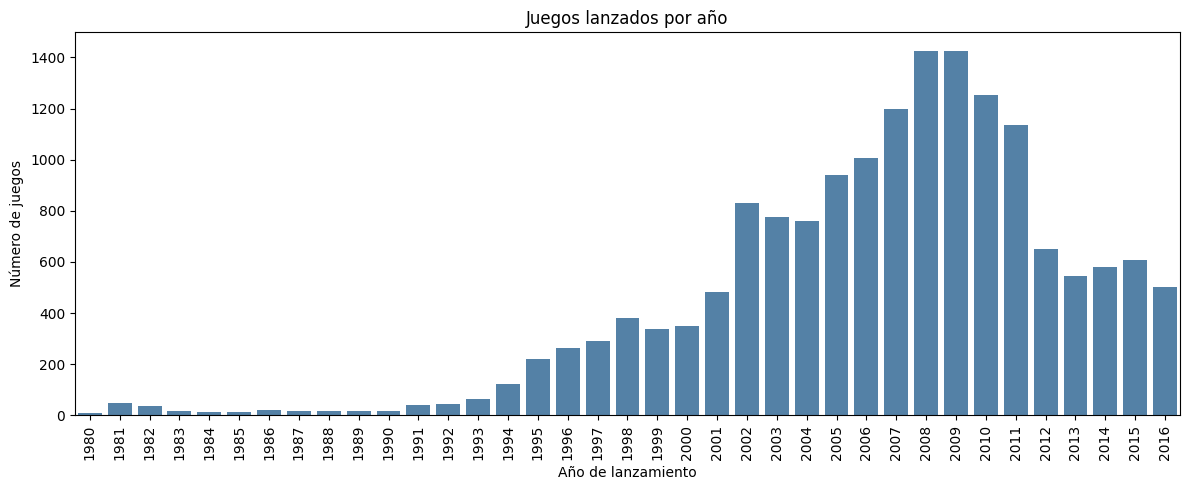

In [19]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.countplot(data=df.dropna(subset=['year_of_release']), x='year_of_release', color='steelblue', ax=ax)
ax.set_title('Juegos lanzados por año')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Número de juegos')
ax.tick_params(axis='x', rotation=90)
fig.tight_layout()
plt.show()

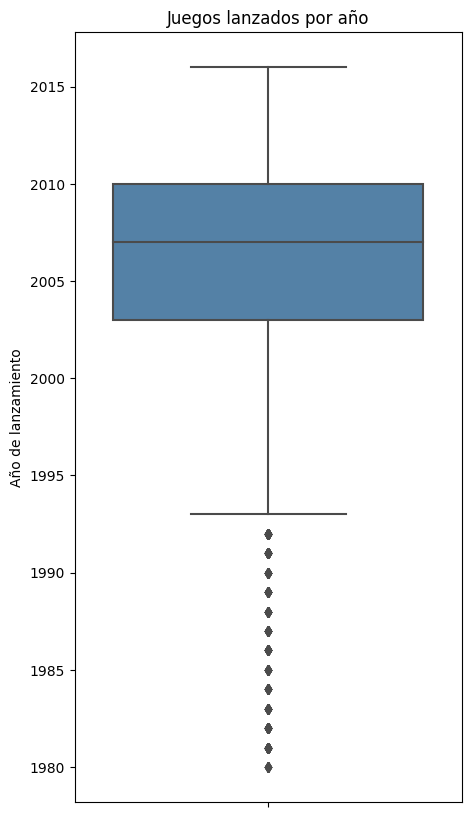

In [20]:
fig, ax = plt.subplots(figsize=(5, 10))
sns.boxplot(data=df, y='year_of_release', color='steelblue', ax=ax)
ax.set_title('Juegos lanzados por año')
ax.set_ylabel('Año de lanzamiento')
plt.show()

Podemos notar un sesgo a la izquierda, y un pico de lanzamientos o registros en el df alrededor del 2008-2009.
La industria de los videojuegos ha ido en aumento con los años por lo que ese sesgo pareciera natural.

**¿Son significativos los datos de cada período?** Antes de 1994 hay menos de 100 juegos por año, por lo que esos periodos tienen muy poco peso y además corresponden a plataformas que ya no existen. Los años con más información son de 2002 en adelante.

El caso a investigar es la caída abrupta de registros desde el año 2012 al 2016.

Para averiguar si la caída de registros fue generalizada o sesgada para alguna consola en particular, se contará las plataformas de esos años.

In [21]:
tabla = df[df['year_of_release']>=2011].groupby(['platform', 'year_of_release']).size().unstack(fill_value=0)
tabla

year_of_release,2011,2012,2013,2014,2015,2016
platform,,,,,,
3DS,116,93,91,80,86,46
DS,153,23,8,0,0,0
PC,139,61,38,47,50,54
PS2,7,0,0,0,0,0
PS3,215,147,126,108,73,38
PS4,0,0,16,75,137,164
PSP,139,106,54,10,3,0
PSV,18,53,63,100,110,85
Wii,143,31,12,6,4,1


Lo visualizamos con un mapa de calor para ver los cambios por plataforma desde el pico del 2011 y la caída de los registros del 2012

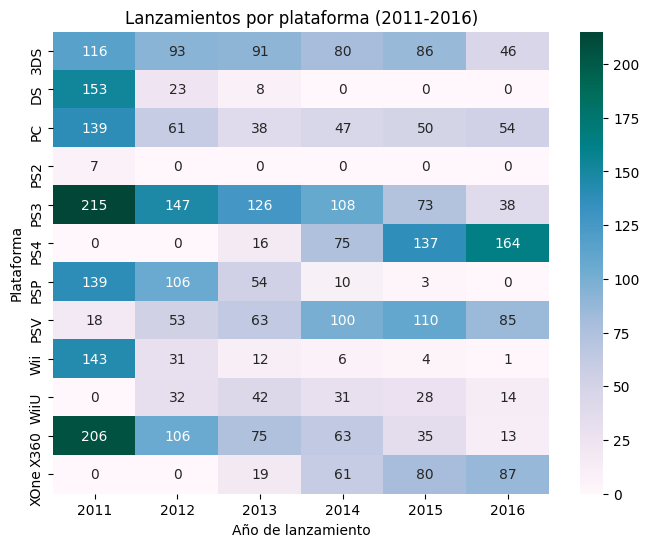

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(tabla, annot=True, fmt='d', cmap='PuBuGn', ax=ax)
ax.set_title('Lanzamientos por plataforma (2011-2016)')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Plataforma')
plt.show()

Viendo el mapa de calor podemos ver los relevos generacionales de las consolas como PS3 a PS4, X360 a XOne, PSP a PSV y la caída de la producción de juegos para Wii y WiiU.

Veamos esos relevos en gráficas.

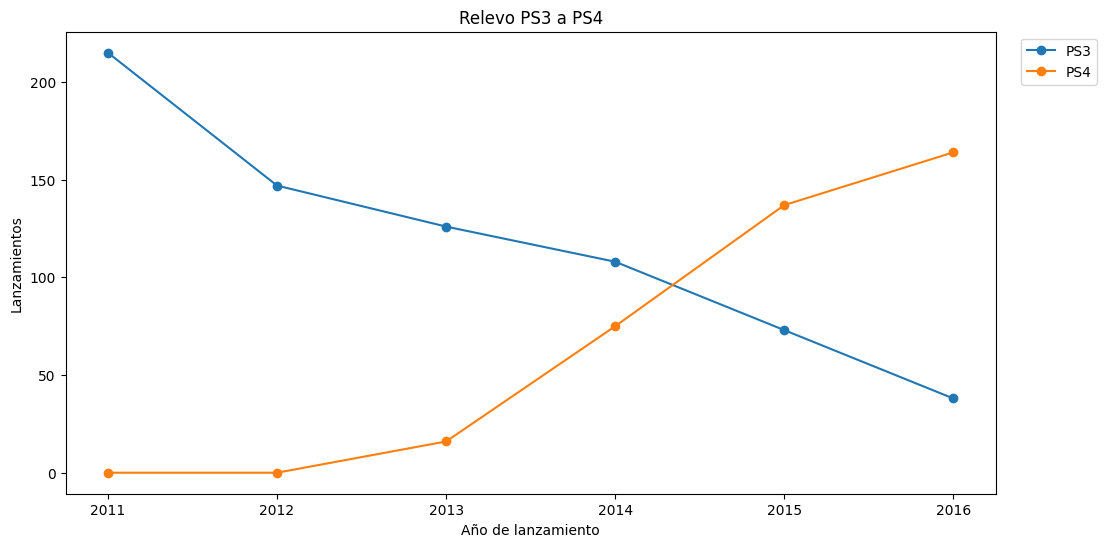

In [23]:
tabla.loc[['PS3', 'PS4']].T.plot(figsize=(12, 6), marker='o')
plt.title('Relevo PS3 a PS4')
plt.ylabel('Lanzamientos')
plt.xlabel('Año de lanzamiento')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

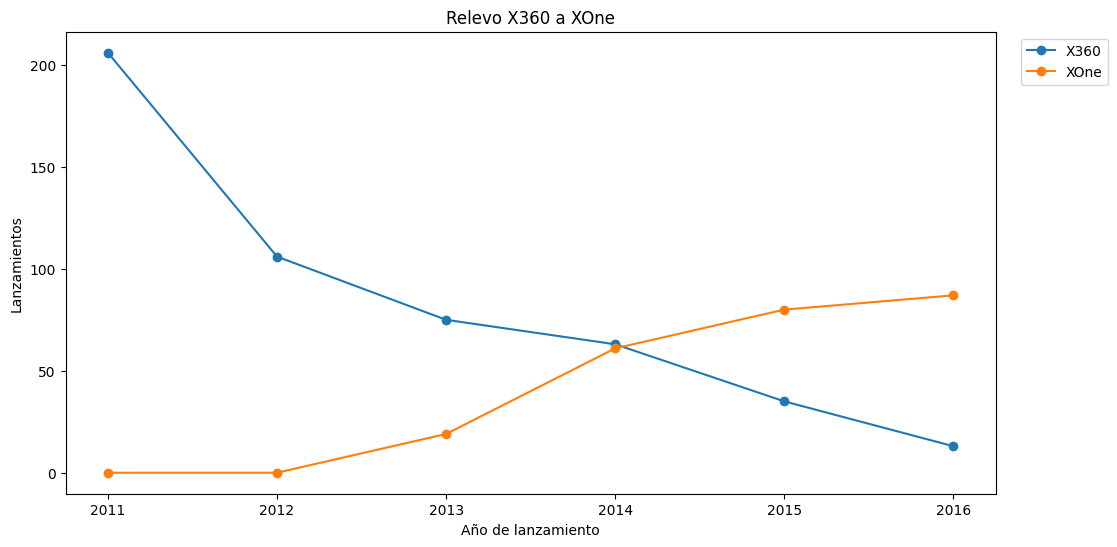

In [24]:
tabla.loc[['X360', 'XOne']].T.plot(figsize=(12, 6), marker='o')
plt.title('Relevo X360 a XOne')
plt.ylabel('Lanzamientos')
plt.xlabel('Año de lanzamiento')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

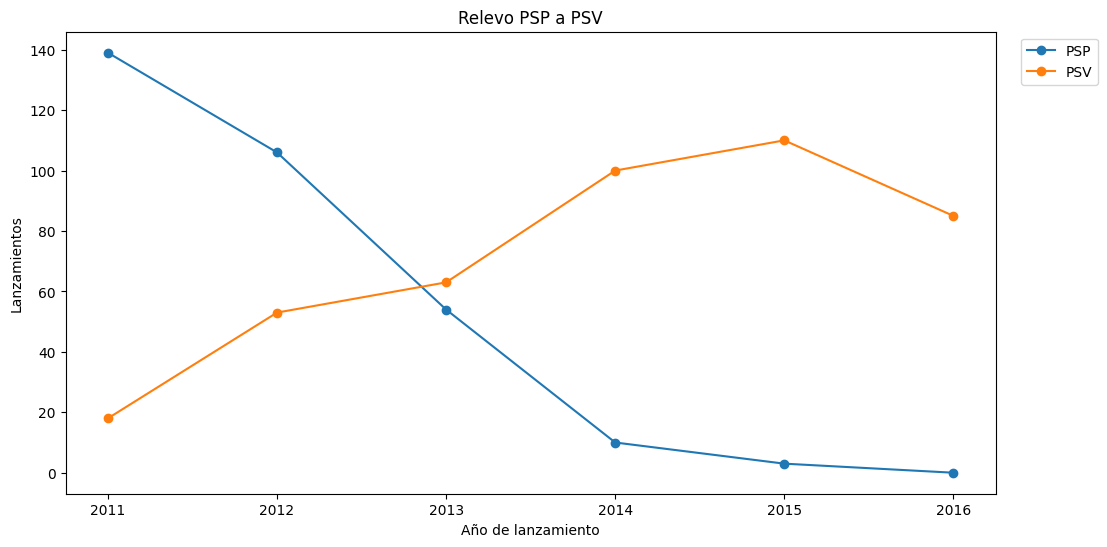

In [25]:
tabla.loc[['PSP', 'PSV']].T.plot(figsize=(12, 6), marker='o')
plt.title('Relevo PSP a PSV')
plt.ylabel('Lanzamientos')
plt.xlabel('Año de lanzamiento')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.show()

La caída desde 2012 no se debe a una sola consola: coincide con el final de la generación PS3/X360/Wii/DS/PSP, que dejaron de recibir juegos, mientras que la nueva generación (PS4, XOne, PSV, WiiU, 3DS) todavía no alcanzaba el mismo volumen. También influyen el crecimiento de los juegos móviles y digitales (que no están en este dataset) y que los datos de 2016 pueden estar incompletos.

### 3.2 Ventas por plataforma

Sumamos las ventas totales de cada plataforma en toda la historia del dataset.

In [26]:
ventas_plataforma = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
display(ventas_plataforma.head(10))

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
Name: total_sales, dtype: float64

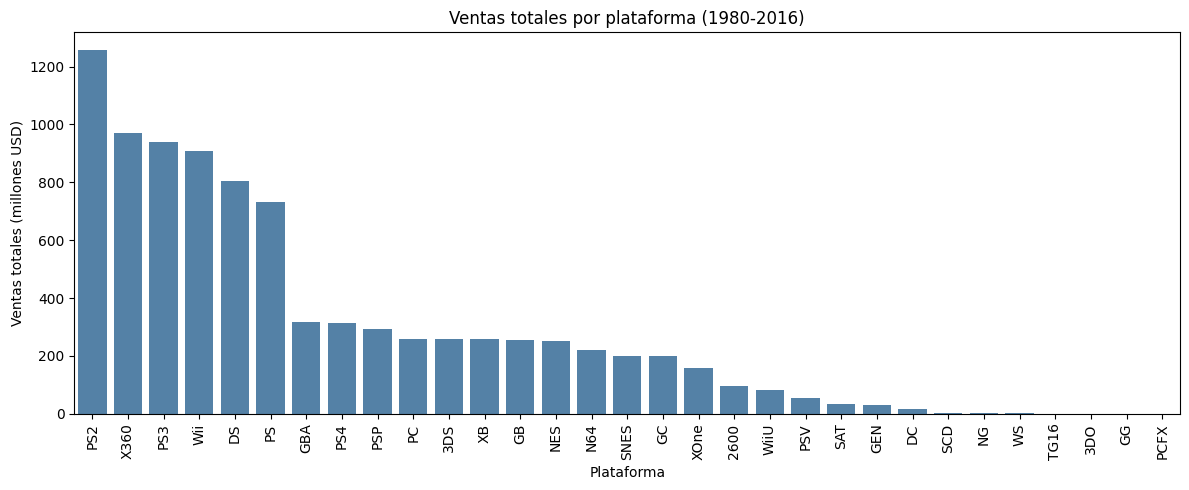

In [27]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(x=ventas_plataforma.index, y=ventas_plataforma.values, color='steelblue', ax=ax)
ax.set_title('Ventas totales por plataforma (1980-2016)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Ventas totales (millones USD)')
ax.tick_params(axis='x', rotation=90)
fig.tight_layout()
plt.show()

Las plataformas con mayores ventas en la historia son PS2, X360, PS3, Wii, DS y PS. Construimos la distribución de sus ventas por año.

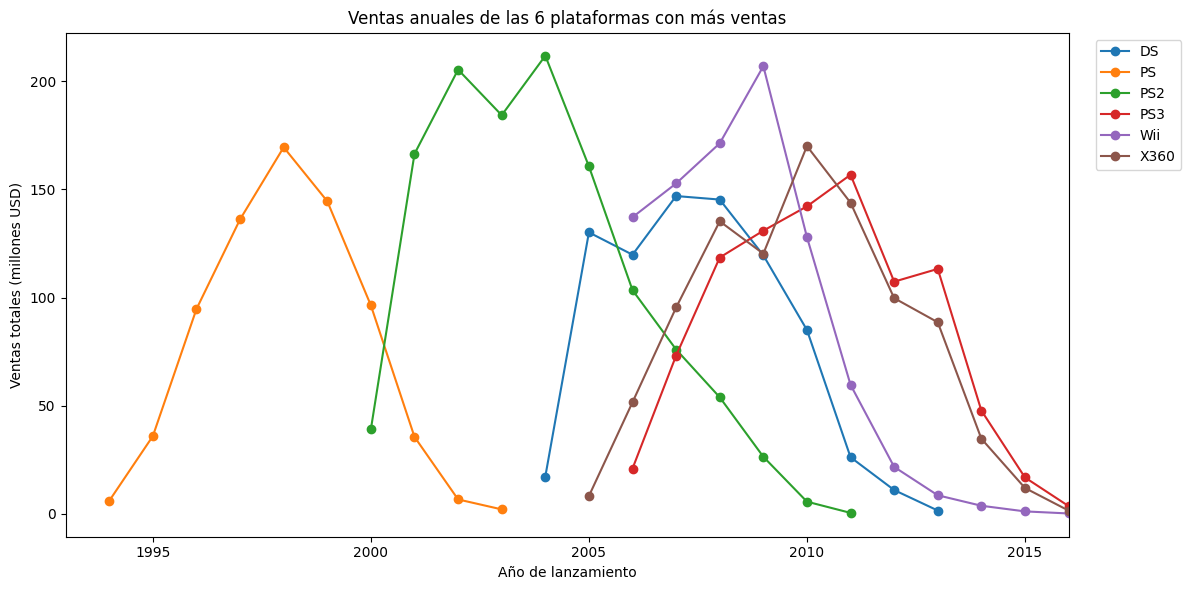

In [28]:
top_plataformas = ventas_plataforma.head(6).index
ventas_anuales = (df[df['platform'].isin(top_plataformas)]
                  .pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum'))

fig, ax = plt.subplots(figsize=(12, 6))
ventas_anuales.plot(marker='o', ax=ax)
ax.set_title('Ventas anuales de las 6 plataformas con más ventas')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Ventas totales (millones USD)')
ax.set_xlim(1993, 2016)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

Todas las plataformas líderes siguen el mismo patrón: crecen durante los primeros años, llegan a un pico y luego caen hasta desaparecer. PS2, PS y DS solían ser muy populares y en 2016 ya no tienen ventas; Wii, PS3 y X360 ya están en la etapa final.

### 3.3 Ciclo de vida de las plataformas

Calculamos el primer y último año con ventas de cada plataforma para saber cuánto tiempo duran.

In [29]:
vida_plataforma = df.groupby('platform')['year_of_release'].agg(['min', 'max'])
vida_plataforma['vida'] = vida_plataforma['max'] - vida_plataforma['min'] + 1
display(vida_plataforma.sort_values('vida', ascending=False))

,min,max,vida
platform,,,
PC,1985,2016,32
DS,1985,2013,29
GB,1988,2001,14
X360,2005,2016,12
PSP,2004,2015,12
PS2,2000,2011,12
NES,1983,1994,12
DC,1998,2008,11
Wii,2006,2016,11


DS aparece con un juego en 1985, lo cual es un error de captura (la consola salió en 2004). PC tiene una vida de 32 años porque no es una consola que se reemplace por generaciones.

Revisamos la vida de las plataformas ya desaparecidas (sin ventas en 2016) que llegaron a ser populares, y cada cuánto aparece una nueva generación de PlayStation como ejemplo.

In [30]:
desaparecidas = vida_plataforma[(vida_plataforma['max'] < 2016) & (vida_plataforma.index.isin(ventas_plataforma.head(15).index))]
desaparecidas = desaparecidas.drop(index='DS', errors='ignore')
display(desaparecidas)
print('Vida mediana de plataformas populares desaparecidas:', desaparecidas['vida'].median(), 'años')

lanzamiento_ps = vida_plataforma.loc[['PS', 'PS2', 'PS3', 'PS4'], 'min']
display(lanzamiento_ps)
print('Años promedio entre generaciones de PlayStation:', lanzamiento_ps.diff().mean().round(1))

,min,max,vida
platform,,,
GB,1988,2001,14
GBA,2000,2007,8
N64,1996,2002,7
NES,1983,1994,12
PS,1994,2003,10
PS2,2000,2011,12
PSP,2004,2015,12
XB,2000,2008,9


Vida mediana de plataformas populares desaparecidas: 11.0 años


platform
PS     1994
PS2    2000
PS3    2006
PS4    2013
Name: min, dtype: Int64

Años promedio entre generaciones de PlayStation: 6.3


**Conclusión del ciclo de vida:**

- Una plataforma exitosa dura alrededor de **10 años** con ventas.
- Las nuevas generaciones aparecen aproximadamente **cada 6 a 7 años** (PS 1994 → PS2 2000 → PS3 2006 → PS4 2013).
- El pico de ventas suele llegar 4 o 5 años después del lanzamiento, y la caída final es más rápida cuando ya existe el sucesor.

### 3.4 Periodo relevante para el pronóstico de 2017

Con lo anterior, para construir un modelo de 2017 no sirve usar todo el histórico: las plataformas viejas ya no venden y el mercado cambió. La generación actual (PS4 y XOne) empezó en **2013**, así que se toma el periodo **2013-2016**. Son 4 años, suficientes para ver tendencias sin incluir plataformas que ya desaparecieron.

In [31]:
df_actual = df[df['year_of_release'] >= 2013].copy()
print('Registros en el periodo 2013-2016:', df_actual.shape[0])
display(df_actual['platform'].value_counts())

Registros en el periodo 2013-2016: 2233


PS4     392
PSV     358
PS3     345
3DS     303
XOne    247
PC      189
X360    186
WiiU    115
PSP      67
Wii      23
DS        8
Name: platform, dtype: int64

### 3.5 Plataformas líderes, en crecimiento y en caída

In [32]:
ventas_actual = df_actual.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
display(ventas_actual)

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64

year_of_release,2013,2014,2015,2016
platform,,,,
3DS,56.57,43.76,27.78,15.14
DS,1.54,0.00,0.00,0.00
PC,12.38,13.28,8.52,5.25
PS3,113.25,47.76,16.82,3.60
PS4,25.99,100.00,118.90,69.25
PSP,3.14,0.24,0.12,0.00
PSV,10.59,11.90,6.25,4.25
Wii,8.59,3.75,1.14,0.18
WiiU,21.65,22.03,16.35,4.60


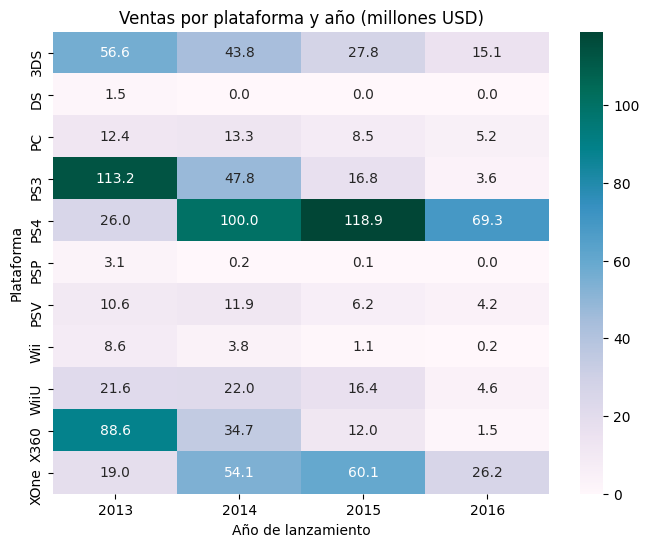

In [33]:
tabla_actual = df_actual.pivot_table(index='platform', columns='year_of_release', values='total_sales', aggfunc='sum', fill_value=0)
display(tabla_actual)

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(tabla_actual, annot=True, fmt='.1f', cmap='PuBuGn', ax=ax)
ax.set_title('Ventas por plataforma y año (millones USD)')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Plataforma')
plt.show()

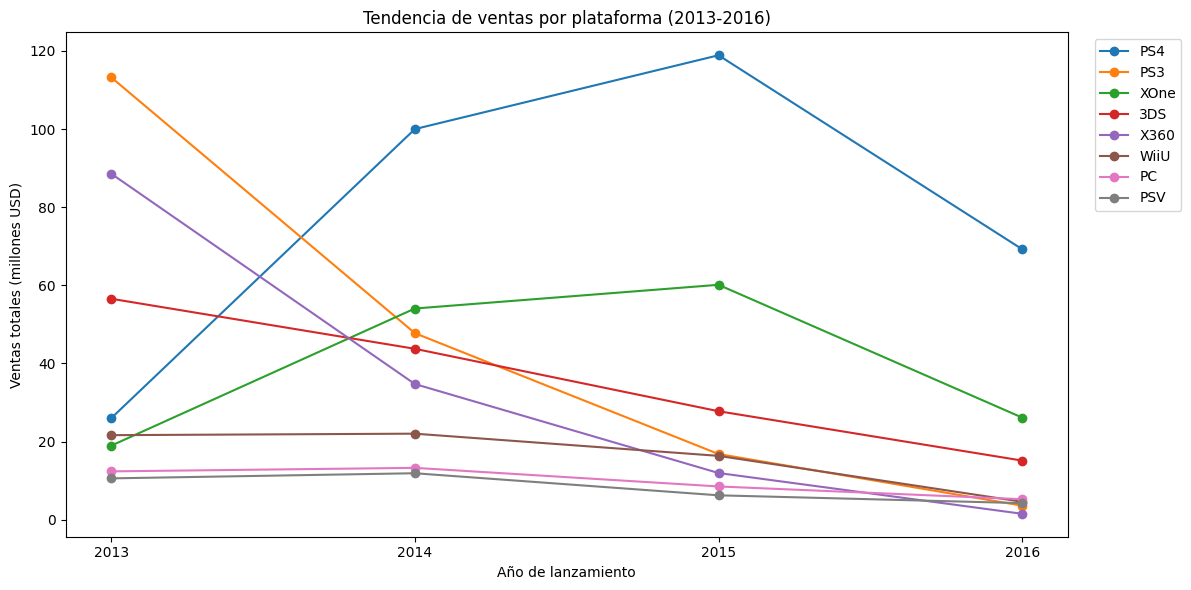

In [34]:
fig, ax = plt.subplots(figsize=(12, 6))
tabla_actual.loc[ventas_actual.head(8).index].T.plot(marker='o', ax=ax)
ax.set_title('Tendencia de ventas por plataforma (2013-2016)')
ax.set_xlabel('Año de lanzamiento')
ax.set_ylabel('Ventas totales (millones USD)')
ax.set_xticks([2013, 2014, 2015, 2016])
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.tight_layout()
plt.show()

**Observaciones:**

- **Líderes en ventas (2013-2016):** PS4 (314 M), PS3 (181 M), XOne (159 M), 3DS (143 M) y X360 (137 M).
- **En crecimiento:** PS4 y XOne crecieron de 2013 a 2015. En 2016 todas bajan, pero hay que recordar que los datos de 2016 pueden estar incompletos.
- **En caída:** PS3, X360, Wii, PSP y DS se están reduciendo hasta desaparecer, porque ya tienen sucesor. 3DS y WiiU también van a la baja.
- **PC** tiene ventas bajas pero estables, sin depender de generaciones.

**Plataformas potencialmente rentables para 2017:** PS4 y XOne (generación actual, mayores ventas), 3DS (líder portátil y muy fuerte en Japón) y PC como mercado estable.

### 3.6 Diagrama de caja de las ventas globales por plataforma

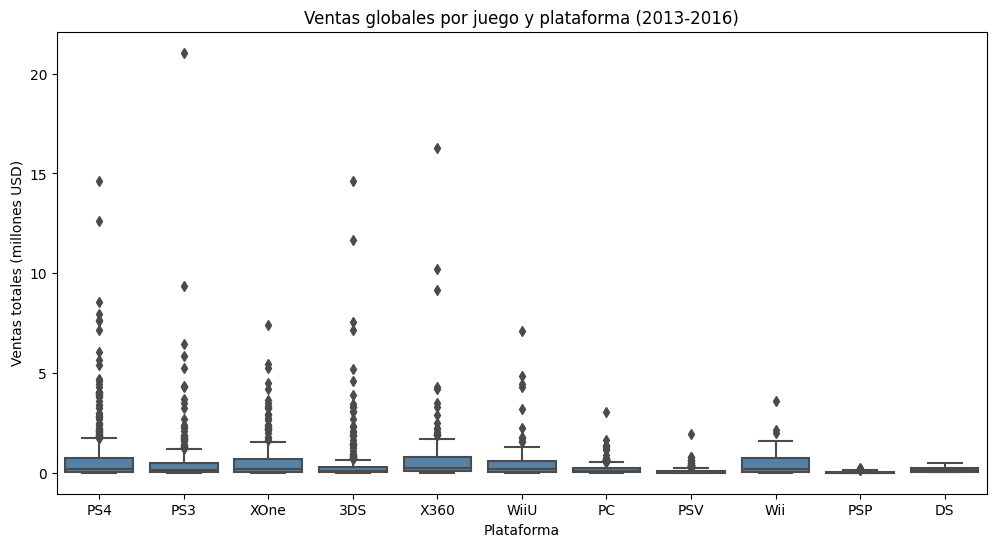

In [35]:
orden = ventas_actual.index

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_actual, x='platform', y='total_sales', order=orden, color='steelblue', ax=ax)
ax.set_title('Ventas globales por juego y plataforma (2013-2016)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Ventas totales (millones USD)')
plt.show()

Los valores atípicos (los grandes éxitos) aplastan la caja, así que hacemos un acercamiento para ver mejor la distribución de la mayoría de los juegos.

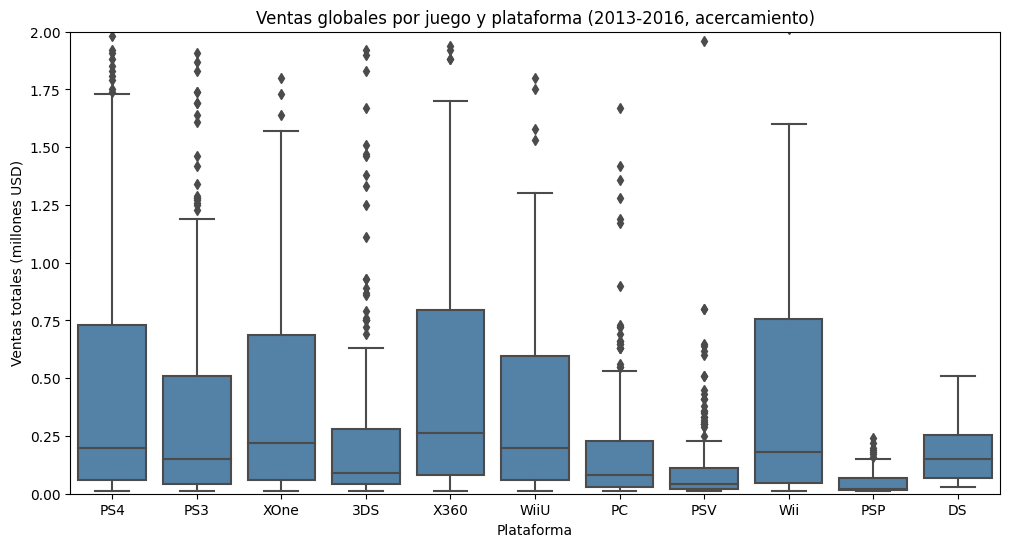

In [36]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=df_actual, x='platform', y='total_sales', order=orden, color='steelblue', ax=ax)
ax.set_ylim(0, 2)
ax.set_title('Ventas globales por juego y plataforma (2013-2016, acercamiento)')
ax.set_xlabel('Plataforma')
ax.set_ylabel('Ventas totales (millones USD)')
plt.show()

In [37]:
estadisticas_plataforma = df_actual.groupby('platform')['total_sales'].agg(['count', 'mean', 'median', 'var', 'std'])
display(estadisticas_plataforma.sort_values('median', ascending=False).round(3))

,count,mean,median,var,std
platform,,,,,
X360,186,0.735,0.265,2.766,1.663
XOne,247,0.645,0.220,1.074,1.036
PS4,392,0.801,0.200,2.590,1.609
WiiU,115,0.562,0.200,1.079,1.039
Wii,23,0.594,0.180,0.838,0.915
DS,8,0.192,0.150,0.030,0.172
PS3,345,0.526,0.150,2.108,1.452
3DS,303,0.473,0.090,1.908,1.381
PC,189,0.209,0.080,0.124,0.352


**Hallazgos:**

- Las diferencias entre plataformas son significativas: la mediana de X360 (0.27 M), XOne (0.22 M), PS4 y WiiU (0.20 M) es varias veces mayor que la de PSV (0.04 M) o PSP (0.02 M).
- En todas las plataformas el **promedio es mucho mayor que la mediana** (PS4: 0.80 M vs 0.20 M). La distribución está sesgada a la derecha: la mayoría de los juegos vende poco y unos cuantos grandes éxitos elevan el promedio.
- La desviación estándar es mayor que el promedio en casi todas las plataformas, lo que confirma la gran dispersión por los valores atípicos.
- Las consolas de sobremesa (PS4, XOne, X360, WiiU) venden más por juego que las portátiles y PC.

### 3.7 Reseñas de usuarios y críticos vs. ventas en PS4

Elegimos PS4 por ser la plataforma líder del periodo.

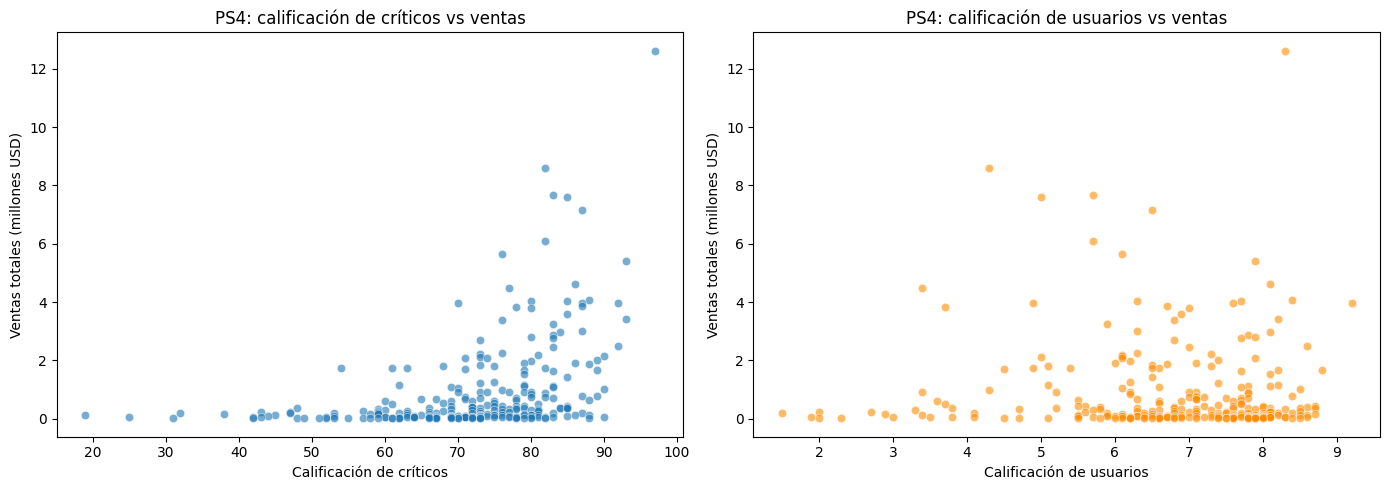

In [38]:
ps4 = df_actual[df_actual['platform']=='PS4']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=ps4, x='critic_score', y='total_sales', alpha=0.6, ax=axes[0])
axes[0].set_title('PS4: calificación de críticos vs ventas')
axes[0].set_xlabel('Calificación de críticos')
axes[0].set_ylabel('Ventas totales (millones USD)')

sns.scatterplot(data=ps4, x='user_score', y='total_sales', alpha=0.6, color='darkorange', ax=axes[1])
axes[1].set_title('PS4: calificación de usuarios vs ventas')
axes[1].set_xlabel('Calificación de usuarios')
axes[1].set_ylabel('Ventas totales (millones USD)')
fig.tight_layout()
plt.show()

In [39]:
print('Correlación críticos-ventas PS4:', round(ps4['critic_score'].corr(ps4['total_sales']), 3))
print('Correlación usuarios-ventas PS4:', round(ps4['user_score'].corr(ps4['total_sales']), 3))

Correlación críticos-ventas PS4: 0.407
Correlación usuarios-ventas PS4: -0.032


**Conclusión:** en PS4 hay una correlación positiva **moderada (0.41)** entre la calificación de los críticos y las ventas: los juegos que más venden casi siempre tienen calificación alta de la crítica (aunque no todos los juegos bien calificados venden mucho). En cambio, la calificación de usuarios **prácticamente no tiene relación** con las ventas (-0.03).

### 3.8 Comparación con otras plataformas

Calculamos las mismas correlaciones para las demás plataformas con suficientes datos.

In [40]:
correlaciones = []
for plataforma in ['PS4', 'XOne', 'PS3', 'X360', '3DS', 'WiiU', 'PC', 'PSV']:
    datos = df_actual[df_actual['platform']==plataforma]
    correlaciones.append({'platform': plataforma,
                          'corr_critic': datos['critic_score'].corr(datos['total_sales']),
                          'corr_user': datos['user_score'].corr(datos['total_sales'])})

correlaciones = pd.DataFrame(correlaciones).set_index('platform')
display(correlaciones.round(3))

,corr_critic,corr_user
platform,,
PS4,0.407,-0.032
XOne,0.417,-0.069
PS3,0.334,0.002
X360,0.350,-0.012
3DS,0.357,0.242
WiiU,0.376,0.419
PC,0.196,-0.094
PSV,0.255,0.001


Ahora comparamos las ventas de los **mismos juegos** de PS4 en otras plataformas.

In [41]:
juegos_ps4 = ps4['name'].unique()
multiplataforma = df_actual[df_actual['name'].isin(juegos_ps4)]
tabla_multi = multiplataforma.pivot_table(index='name', columns='platform', values='total_sales', aggfunc='sum')

comparacion = tabla_multi.agg(['count', 'mean', 'median']).T.sort_values('count', ascending=False)
display(comparacion.round(3))

,count,mean,median
PS4,392.0,0.801,0.200
XOne,217.0,0.596,0.210
PS3,165.0,0.772,0.250
PC,105.0,0.214,0.100
X360,100.0,1.073,0.425
PSV,82.0,0.145,0.090
WiiU,35.0,0.329,0.240
3DS,19.0,0.289,0.230
Wii,10.0,1.117,0.755
PSP,2.0,0.120,0.120


Juegos lanzados en PS4 y XOne: 217
Correlación de ventas del mismo juego en PS4 y XOne: 0.956
Ventas promedio de esos juegos en PS4: 1.181 | XOne: 0.596
Porcentaje de juegos que venden más en PS4 que en XOne: 93.1


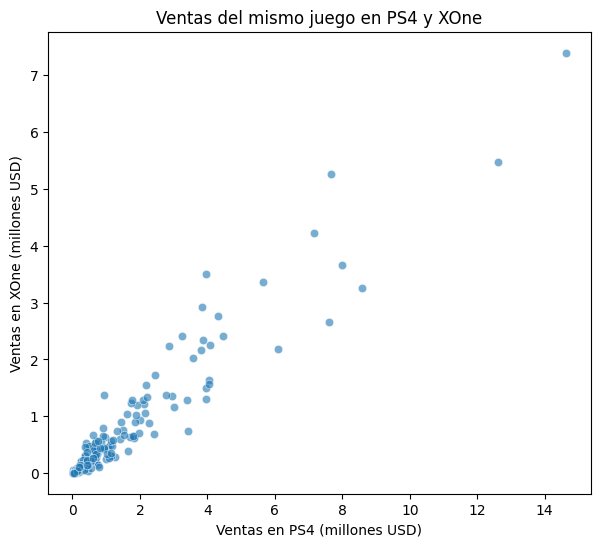

In [42]:
juegos_ps4_xone = tabla_multi[['PS4', 'XOne']].dropna()
print('Juegos lanzados en PS4 y XOne:', juegos_ps4_xone.shape[0])
print('Correlación de ventas del mismo juego en PS4 y XOne:', round(juegos_ps4_xone['PS4'].corr(juegos_ps4_xone['XOne']), 3))
print('Ventas promedio de esos juegos en PS4:', round(juegos_ps4_xone['PS4'].mean(), 3), '| XOne:', round(juegos_ps4_xone['XOne'].mean(), 3))
print('Porcentaje de juegos que venden más en PS4 que en XOne:', round((juegos_ps4_xone['PS4'] > juegos_ps4_xone['XOne']).mean() * 100, 1))

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=juegos_ps4_xone, x='PS4', y='XOne', alpha=0.6, ax=ax)
ax.set_title('Ventas del mismo juego en PS4 y XOne')
ax.set_xlabel('Ventas en PS4 (millones USD)')
ax.set_ylabel('Ventas en XOne (millones USD)')
plt.show()

**Conclusiones:**

- En todas las plataformas la calificación de los críticos tiene una correlación positiva moderada con las ventas (entre 0.2 y 0.42). Es el mejor indicador de los dos.
- La calificación de usuarios no influye en PS4, XOne, PS3, X360, PC ni PSV. Solo en las consolas de Nintendo (3DS 0.24 y WiiU 0.42) tiene algo de relación.
- Los juegos de PS4 se lanzan también sobre todo en XOne (217), PS3 (165) y PC (105).
- Las ventas del mismo juego en PS4 y XOne están muy relacionadas (correlación 0.96): un juego exitoso en una plataforma suele serlo también en la otra. Aun así, el 93 % de esos juegos vende más en PS4, y en promedio venden el doble (1.18 M vs 0.60 M).
- En X360 y PS3 el promedio de los juegos compartidos es alto porque a la generación anterior solo siguieron llegando los grandes lanzamientos (deportes anuales, shooters). Las versiones de PC y PSV venden mucho menos.

### 3.9 Distribución por género

In [43]:
generos = df_actual.groupby('genre')['total_sales'].agg(['count', 'sum', 'mean', 'median']).sort_values('median', ascending=False)
display(generos.round(3))

,count,sum,mean,median
genre,,,,
Shooter,187,232.98,1.246,0.450
Sports,214,150.65,0.704,0.240
Platform,74,42.63,0.576,0.225
Role-Playing,292,145.89,0.500,0.125
Fighting,80,35.31,0.441,0.125
Racing,85,39.89,0.469,0.120
Action,766,321.87,0.420,0.110
Simulation,62,21.76,0.351,0.100
Misc,155,62.82,0.405,0.100


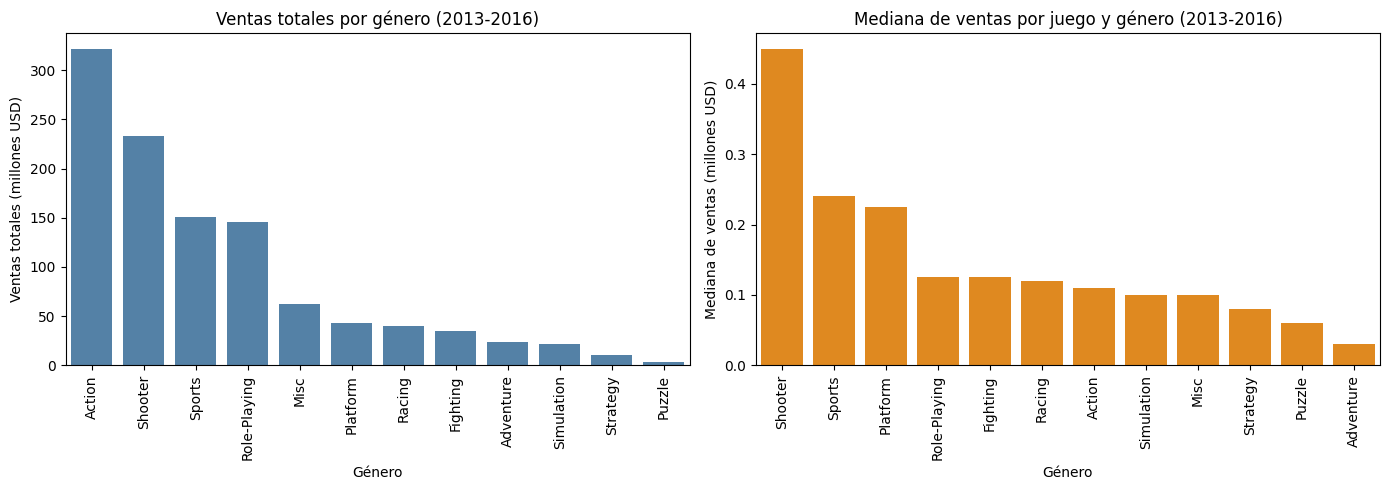

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
generos_suma = generos.sort_values('sum', ascending=False)
sns.barplot(x=generos_suma.index, y=generos_suma['sum'], color='steelblue', ax=axes[0])
axes[0].set_title('Ventas totales por género (2013-2016)')
axes[0].set_xlabel('Género')
axes[0].set_ylabel('Ventas totales (millones USD)')
axes[0].tick_params(axis='x', rotation=90)

sns.barplot(x=generos.index, y=generos['median'], color='darkorange', ax=axes[1])
axes[1].set_title('Mediana de ventas por juego y género (2013-2016)')
axes[1].set_xlabel('Género')
axes[1].set_ylabel('Mediana de ventas (millones USD)')
axes[1].tick_params(axis='x', rotation=90)
fig.tight_layout()
plt.show()

**Conclusiones sobre géneros:**

- **Action** es el género con más juegos (766) y más ventas totales (322 M), pero su mediana por juego es baja (0.11 M): vende mucho porque hay muchos juegos, no porque cada uno sea rentable.
- **Shooter** es el género más rentable por juego: mediana de 0.45 M y promedio de 1.25 M. Le siguen **Sports** (0.24 M) y **Platform** (0.23 M).
- Los géneros con ventas bajas son **Adventure** (mediana 0.03 M), **Puzzle** y **Strategy**.
- Se puede generalizar que los géneros de acción intensa y competitiva (Shooter, Sports) venden más por juego, mientras que los géneros de nicho o más pausados venden menos. Para medir rentabilidad conviene usar la mediana y no la suma total.

## Paso 4. Perfil de usuario por región

Se trabaja con el periodo 2013-2016. Para cada región (NA, UE, JP) se calculan las 5 plataformas y los 5 géneros principales con su cuota de mercado, y el efecto de la clasificación ESRB.

In [45]:
regiones = {'na_sales': 'Norteamérica', 'eu_sales': 'Europa', 'jp_sales': 'Japón'}

def top_region(columna_grupo, region, n=5):
    ventas = df_actual.groupby(columna_grupo)[region].sum().sort_values(ascending=False)
    cuota = (ventas / ventas.sum() * 100).round(1)
    return pd.DataFrame({'ventas': ventas.round(2), 'cuota_%': cuota}).head(n)

### 4.1 Las cinco plataformas principales

In [46]:
for region, nombre in regiones.items():
    print(nombre)
    display(top_region('platform', region))

Norteamérica


,ventas,cuota_%
platform,,
PS4,108.74,24.8
XOne,93.12,21.3
X360,81.66,18.7
PS3,63.50,14.5
3DS,38.20,8.7


Europa


,ventas,cuota_%
platform,,
PS4,141.09,36.0
PS3,67.81,17.3
XOne,51.59,13.2
X360,42.52,10.8
3DS,30.96,7.9


Japón


,ventas,cuota_%
platform,,
3DS,67.81,48.2
PS3,23.35,16.6
PSV,18.59,13.2
PS4,15.96,11.3
WiiU,10.88,7.7


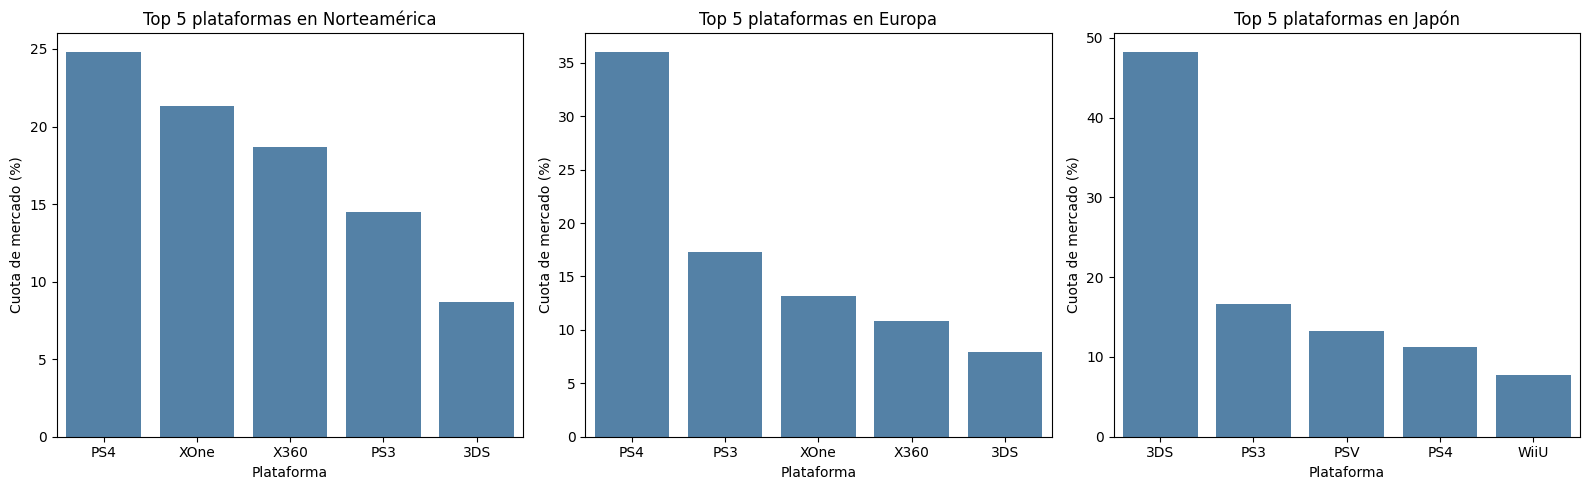

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (region, nombre) in zip(axes, regiones.items()):
    top = top_region('platform', region)
    sns.barplot(x=top.index, y=top['cuota_%'], color='steelblue', ax=ax)
    ax.set_title(f'Top 5 plataformas en {nombre}')
    ax.set_xlabel('Plataforma')
    ax.set_ylabel('Cuota de mercado (%)')
fig.tight_layout()
plt.show()

**Variaciones en las cuotas de mercado:**

- **Norteamérica:** PS4 (24.8 %), XOne (21.3 %), X360 (18.7 %), PS3 (14.5 %) y 3DS (8.7 %). Es el mercado donde Xbox tiene más fuerza: XOne casi empata con PS4, lo cual es natural porque Microsoft es una empresa estadounidense.
- **Europa:** PS4 domina con el 36 %, seguida de PS3 (17.3 %), XOne (13.2 %), X360 (10.8 %) y 3DS (7.9 %). PlayStation es mucho más fuerte que Xbox.
- **Japón:** el mercado es completamente diferente. 3DS tiene casi la mitad (48.2 %), seguida de PS3 (16.6 %), PSV (13.2 %), PS4 (11.3 %) y WiiU (7.7 %). Dominan las consolas portátiles y las marcas japonesas; Xbox ni siquiera aparece.

### 4.2 Los cinco géneros principales

In [48]:
for region, nombre in regiones.items():
    print(nombre)
    display(top_region('genre', region))

Norteamérica


,ventas,cuota_%
genre,,
Action,126.05,28.8
Shooter,109.74,25.1
Sports,65.27,14.9
Role-Playing,46.40,10.6
Misc,27.49,6.3


Europa


,ventas,cuota_%
genre,,
Action,118.13,30.1
Shooter,87.86,22.4
Sports,60.52,15.4
Role-Playing,36.97,9.4
Racing,20.19,5.1


Japón


,ventas,cuota_%
genre,,
Role-Playing,51.04,36.3
Action,40.49,28.8
Misc,9.20,6.5
Fighting,7.65,5.4
Shooter,6.61,4.7


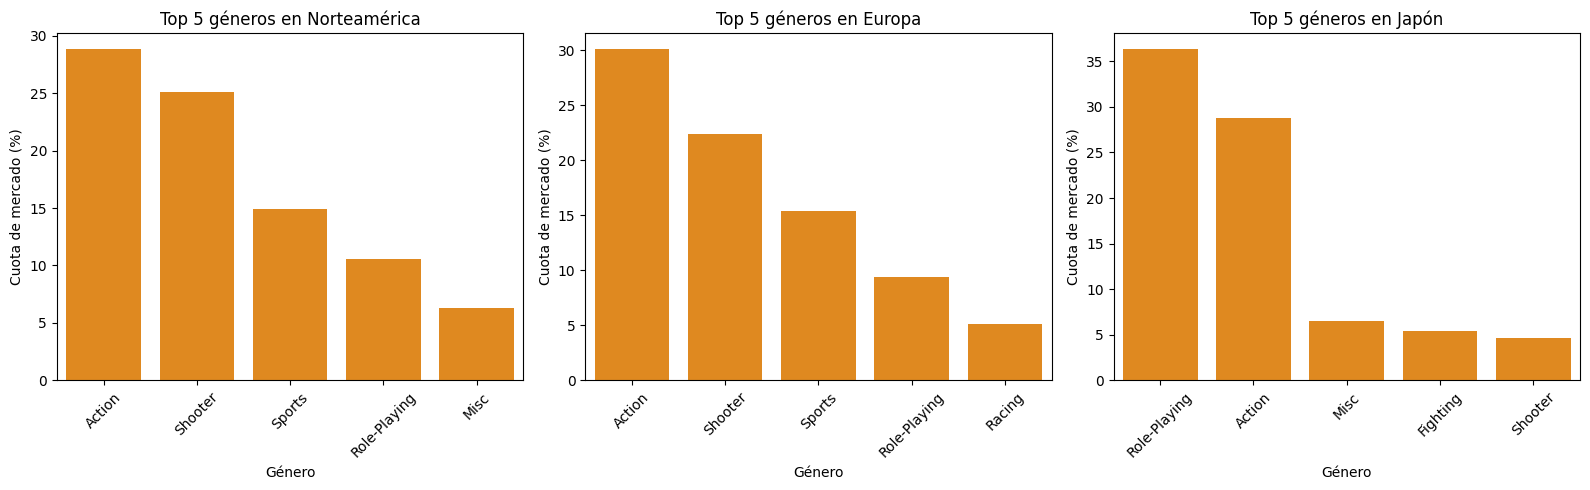

In [49]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (region, nombre) in zip(axes, regiones.items()):
    top = top_region('genre', region)
    sns.barplot(x=top.index, y=top['cuota_%'], color='darkorange', ax=ax)
    ax.set_title(f'Top 5 géneros en {nombre}')
    ax.set_xlabel('Género')
    ax.set_ylabel('Cuota de mercado (%)')
    ax.tick_params(axis='x', rotation=45)
fig.tight_layout()
plt.show()

**Diferencias entre regiones:**

- **Norteamérica y Europa** tienen gustos casi idénticos: Action (29-30 %), Shooter (22-25 %), Sports (15 %) y Role-Playing (~10 %). La única diferencia es el quinto lugar: Misc en NA y Racing en EU.
- **Japón** prefiere **Role-Playing** (36.3 %, el primer lugar), seguido de Action (28.8 %), Misc, Fighting y Shooter (solo 4.7 %). Los juegos de rol japoneses (JRPG) y las portátiles explican esta preferencia, mientras que los shooters, muy populares en occidente, tienen poco éxito en Japón.

### 4.3 Efecto de la clasificación ESRB en las ventas por región

Recordatorio de las clasificaciones: E (todos), E10+ (10 años o más), T (adolescentes), M (adultos, 17+). `unknown` son los juegos sin clasificación.

In [50]:
ventas_rating = df_actual.pivot_table(index='rating', values=['na_sales', 'eu_sales', 'jp_sales'], aggfunc=['sum', 'mean'])
display(ventas_rating.round(3))

sum                       mean                  
        eu_sales jp_sales na_sales eu_sales jp_sales na_sales
rating                                                       
E          83.36    15.14    79.05    0.276    0.050    0.262
E10+       42.69     5.89    54.24    0.169    0.023    0.215
M         145.32    14.11   165.21    0.394    0.038    0.448
T          41.95    20.59    49.79    0.126    0.062    0.150
unknown    78.91    85.05    89.42    0.081    0.087    0.092

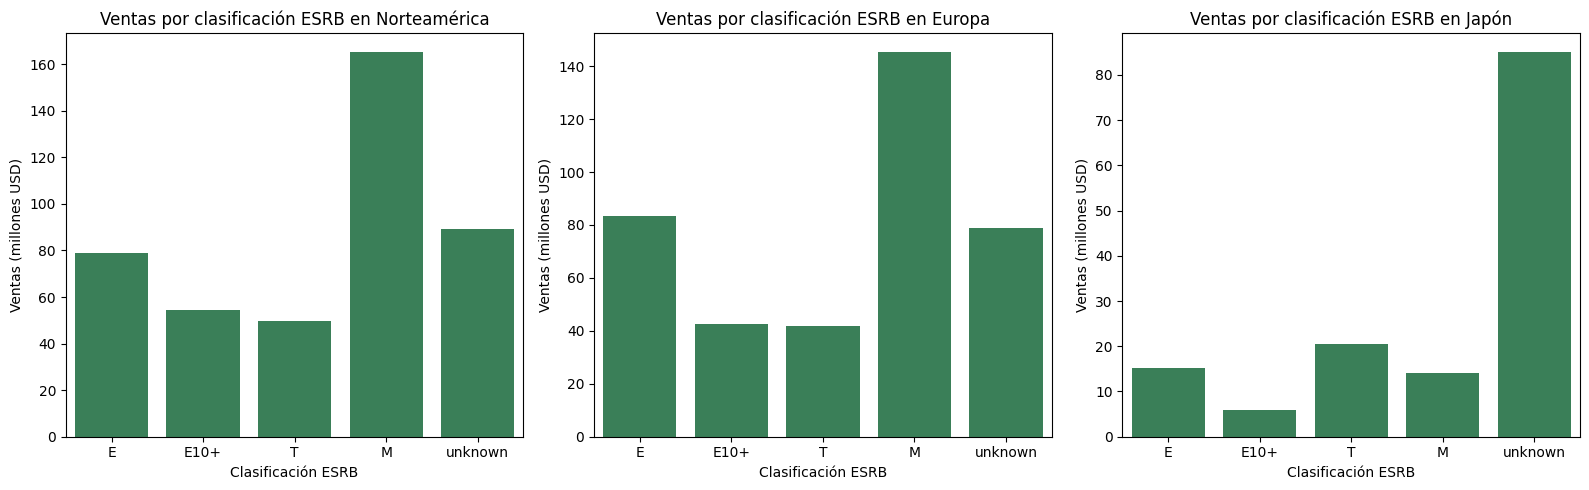

In [51]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
orden_rating = ['E', 'E10+', 'T', 'M', 'unknown']
for ax, (region, nombre) in zip(axes, regiones.items()):
    ventas_rating_region = df_actual.groupby('rating')[region].sum().reindex(orden_rating)
    sns.barplot(x=ventas_rating_region.index, y=ventas_rating_region.values, color='seagreen', ax=ax)
    ax.set_title(f'Ventas por clasificación ESRB en {nombre}')
    ax.set_xlabel('Clasificación ESRB')
    ax.set_ylabel('Ventas (millones USD)')
fig.tight_layout()
plt.show()

**¿Afectan las clasificaciones ESRB a las ventas?**

- **En Norteamérica y Europa sí:** los juegos **M** (adultos) son los que más venden en total y también por juego (promedio de 0.45 M en NA y 0.39 M en EU), lo que coincide con la popularidad de los shooters y juegos de acción. Les siguen los juegos E.
- **En Japón la clasificación ESRB casi no explica las ventas:** la mayor parte de las ventas viene de juegos `unknown`, porque muchos juegos japoneses no se venden en Norteamérica y por eso no tienen clasificación ESRB (en Japón se usa CERO). Entre los juegos clasificados, T tiene ligeramente más ventas.
- Esto indica que la clasificación en sí no es lo que provoca las ventas, sino que refleja el tipo de juego que prefiere cada región.

## Paso 5. Prueba de hipótesis

Se usan los datos del periodo relevante (2013-2016) y se descartan los juegos sin calificación de usuarios.

**Umbral alfa:** se elige **α = 0.05**, el valor estándar: aceptamos un 5 % de probabilidad de rechazar la hipótesis nula cuando en realidad es cierta.

**Criterio utilizado:** como se comparan las medias de **dos muestras independientes** (los juegos de una plataforma o género no son los mismos que los de la otra), se usa la **prueba t de Student para muestras independientes** (`st.ttest_ind`). Antes se aplica la **prueba de Levene** para saber si las varianzas son iguales: si no lo son, se usa la versión de Welch (`equal_var=False`).

**Cómo se formulan las hipótesis:** la hipótesis nula (H₀) siempre plantea igualdad de medias y la alternativa (H₁) plantea que son diferentes, porque la prueba t mide si la diferencia observada es lo bastante grande para descartar la igualdad.

In [52]:
alpha = 0.05

### 5.1 Calificaciones promedio de usuarios: Xbox One vs PC

- **H₀:** las calificaciones promedio de los usuarios para Xbox One y PC son iguales.
- **H₁:** las calificaciones promedio de los usuarios para Xbox One y PC son diferentes.

In [53]:
user_xone = df_actual[df_actual['platform']=='XOne']['user_score'].dropna()
user_pc = df_actual[df_actual['platform']=='PC']['user_score'].dropna()

print('Tamaño de muestra XOne:', len(user_xone), '| PC:', len(user_pc))
print('Media XOne:', round(user_xone.mean(), 3), '| PC:', round(user_pc.mean(), 3))
print('Varianza XOne:', round(np.var(user_xone, ddof=1), 3), '| PC:', round(np.var(user_pc, ddof=1), 3))
print('Desviación estándar XOne:', round(np.std(user_xone, ddof=1), 3), '| PC:', round(np.std(user_pc, ddof=1), 3))

Tamaño de muestra XOne: 182 | PC: 155
Media XOne: 6.521 | PC: 6.27
Varianza XOne: 1.907 | PC: 3.036
Desviación estándar XOne: 1.381 | PC: 1.742


In [54]:
levene_plataforma = st.levene(user_xone, user_pc)
print('Levene p-value:', levene_plataforma.pvalue)
varianzas_iguales = levene_plataforma.pvalue > alpha

resultado_plataforma = st.ttest_ind(user_xone, user_pc, equal_var=varianzas_iguales)
print('valor p:', resultado_plataforma.pvalue)

if resultado_plataforma.pvalue < alpha:
    print('Rechazamos la hipótesis nula')
else:
    print('No podemos rechazar la hipótesis nula')

Levene p-value: 0.003897553110130418
valor p: 0.14759594013430463
No podemos rechazar la hipótesis nula


**Resultado:** la prueba de Levene da un valor p menor a 0.05, así que las varianzas son distintas (PC tiene calificaciones más dispersas) y se usa la prueba de Welch. El valor p (≈ 0.15) es mayor que α, por lo que **no podemos rechazar la hipótesis nula**: no hay evidencia de que las calificaciones promedio de usuarios de Xbox One (6.52) y PC (6.27) sean diferentes.

### 5.2 Calificaciones promedio de usuarios: Acción vs Deportes

- **H₀:** las calificaciones promedio de los usuarios para los géneros Acción y Deportes son iguales.
- **H₁:** las calificaciones promedio de los usuarios para los géneros Acción y Deportes son diferentes.

In [55]:
user_action = df_actual[df_actual['genre']=='Action']['user_score'].dropna()
user_sports = df_actual[df_actual['genre']=='Sports']['user_score'].dropna()

print('Tamaño de muestra Action:', len(user_action), '| Sports:', len(user_sports))
print('Media Action:', round(user_action.mean(), 3), '| Sports:', round(user_sports.mean(), 3))
print('Varianza Action:', round(np.var(user_action, ddof=1), 3), '| Sports:', round(np.var(user_sports, ddof=1), 3))
print('Desviación estándar Action:', round(np.std(user_action, ddof=1), 3), '| Sports:', round(np.std(user_sports, ddof=1), 3))

Tamaño de muestra Action: 389 | Sports: 160
Media Action: 6.838 | Sports: 5.238
Varianza Action: 1.769 | Sports: 3.181
Desviación estándar Action: 1.33 | Sports: 1.783


In [56]:
levene_genero = st.levene(user_action, user_sports)
print('Levene p-value:', levene_genero.pvalue)
varianzas_iguales = levene_genero.pvalue > alpha

resultado_genero = st.ttest_ind(user_action, user_sports, equal_var=varianzas_iguales)
print('valor p:', resultado_genero.pvalue)

if resultado_genero.pvalue < alpha:
    print('Rechazamos la hipótesis nula')
else:
    print('No podemos rechazar la hipótesis nula')

Levene p-value: 4.2566688218274047e-07
valor p: 1.4460039700704315e-20
Rechazamos la hipótesis nula


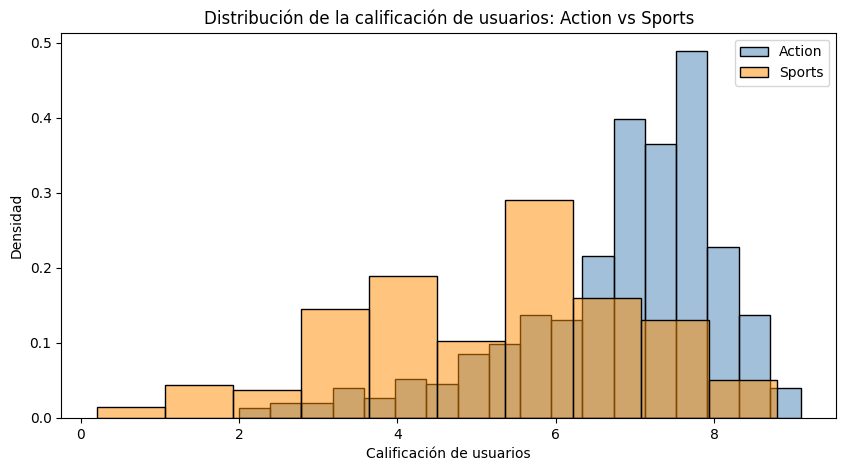

In [57]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(user_action, color='steelblue', label='Action', stat='density', alpha=0.5, ax=ax)
sns.histplot(user_sports, color='darkorange', label='Sports', stat='density', alpha=0.5, ax=ax)
ax.set_title('Distribución de la calificación de usuarios: Action vs Sports')
ax.set_xlabel('Calificación de usuarios')
ax.set_ylabel('Densidad')
ax.legend()
plt.show()

**Resultado:** las varianzas también son distintas (Sports es más disperso), así que se usa la prueba de Welch. El valor p es prácticamente cero (≈ 1.4e-20), mucho menor que α, por lo que **rechazamos la hipótesis nula**: las calificaciones promedio de usuarios de Acción (6.84) y Deportes (5.24) **son diferentes**. Los usuarios califican mejor los juegos de acción.

## Paso 6. Conclusión general

**Preparación de los datos**
- Se pasaron los nombres de columnas a minúsculas, `year_of_release` a `Int64` y `user_score` a `float` (los `tbd` se trataron como nulos porque no tienen calificación).
- Se dejaron como nulos los años y calificaciones faltantes para no distorsionar el análisis; los `rating` faltantes se marcaron como `unknown`. Se eliminó un duplicado de *Madden NFL 13* y se creó la columna `total_sales`.

**Mercado y plataformas**
- Los lanzamientos crecieron hasta 2008-2009 y cayeron desde 2012 por el cambio de generación y el auge de los juegos móviles/digitales.
- Una plataforma vive alrededor de 10 años y aparece una nueva generación cada 6 o 7 años. Por eso, para pronosticar 2017 se tomó el periodo **2013-2016**.
- **PS4** es la líder y, junto con **XOne**, es la plataforma con futuro. PS3, X360, Wii y las portátiles antiguas van en caída. 3DS sigue siendo importante, sobre todo en Japón.
- Las ventas por juego tienen una distribución muy sesgada: pocos éxitos concentran la mayoría de las ventas.

**Factores de éxito**
- La **calificación de la crítica** tiene una relación positiva moderada con las ventas (≈ 0.4 en PS4 y XOne). La calificación de usuarios casi no influye, excepto en consolas de Nintendo.
- **Shooter** es el género más rentable por juego, seguido de Sports y Platform. Action vende mucho en total por su volumen de lanzamientos. Adventure, Puzzle y Strategy venden poco.

**Perfiles por región**
- **Norteamérica:** PS4 y XOne casi empatadas; prefiere Action, Shooter y Sports; los juegos M venden más.
- **Europa:** PS4 domina; mismos géneros que NA; los juegos M venden más.
- **Japón:** domina 3DS y las portátiles; prefiere Role-Playing; la clasificación ESRB no aplica a buena parte de su mercado.

**Hipótesis**
- No hay diferencia significativa entre las calificaciones promedio de usuarios de Xbox One y PC.
- Sí hay diferencia entre Acción y Deportes: los usuarios califican mejor los juegos de acción.

**Recomendaciones para la campaña 2017**
- Enfocar la mayor parte del presupuesto en juegos de **PS4 y XOne** en Norteamérica y Europa, priorizando **Shooter, Action y Sports** con clasificación **M** o **E** y buenas calificaciones de la crítica.
- Para **Japón**, hacer una campaña separada para **3DS** (y en menor medida PS4/PSV) con juegos de **Role-Playing** y Action.
- Mantener una presencia menor en **PC** como mercado estable, y reducir la inversión en plataformas de generación anterior (PS3, X360, Wii).
- Usar la calificación de la crítica como señal temprana para elegir qué juegos promocionar.